In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<h2 style="color:green" align="center">Predicting if a person would buy life insurnace based on his age using logistic regression</h2>

Above is a binary logistic regression problem as there are only two possible outcomes (i.e. if person buys insurance or he/she doesn't).

---
# Part 1 — Quick start: will a person buy life insurance?

📘 **Problem.** We want to predict whether a person **buys life insurance (1)** or **does not (0)** from their **age**.

This is a **binary classification** problem: the output has only two possible values, $y \in \{0, 1\}$.

**Why not plain linear regression?** A straight line $y = mx + b$ can output values like $-0.4$ or $1.7$, which make no sense as a "yes/no" answer or as a probability. Logistic regression keeps the linear part but **squashes** it into the range $(0,1)$ with the **sigmoid** function, so the output can be read as a probability:

$$
h_\theta(x) = P(y = 1 \mid x;\theta) = \sigma(\theta^T x) = \frac{1}{1+e^{-\theta^T x}}
$$

The whole model at a glance (from the lecture slides):

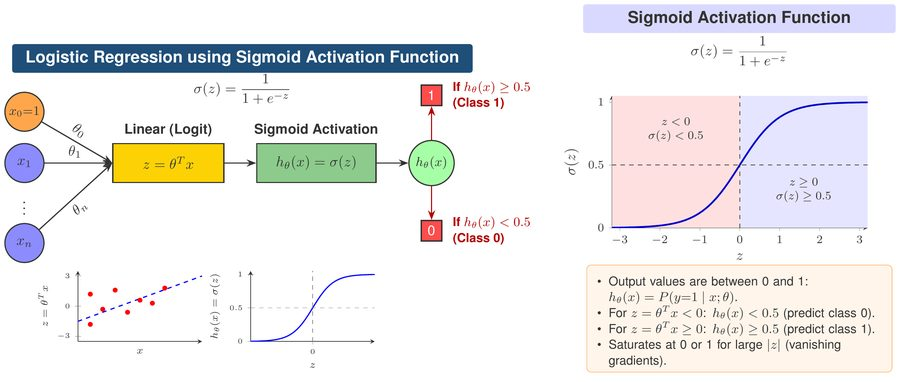

**Read the diagram left → right:**
1. Inputs $x_1,\dots,x_n$ (plus a constant $x_0 = 1$ for the bias) are multiplied by weights $\theta_0,\dots,\theta_n$.
2. **Linear part (logit):** $z = \theta^T x = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n$
3. **Sigmoid activation:** $h_\theta(x) = \sigma(z)$ — a number between 0 and 1.
4. **Decision rule:** predict class **1** if $h_\theta(x) \ge 0.5$, otherwise class **0**.

Let's first see this working with scikit-learn, then in Parts 2–6 we will open the "black box" and build it ourselves.

In [2]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from sklearn.linear_model import LogisticRegression


# Load a dataset and visualize

In [3]:
df = pd.read_csv("insurance_data.csv")
df.head()

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1


Text(0, 0.5, 'Insurance Purchase')

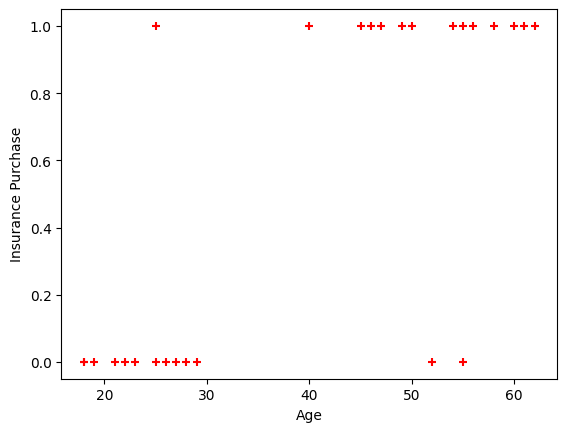

In [5]:
plt.scatter(df.age,df.bought_insurance,marker='+',color='red')
plt.xlabel("Age")
plt.ylabel("Insurance Purchase")

In [37]:
X_train, X_test, y_train, y_test = train_test_split(df[['age']],df.bought_insurance,train_size=0.8,random_state=4)

In [38]:
print(X_test)


    age
24   50
16   25
22   40
0    22
3    52
10   18


### Insurance Purchase Prediction

Create a Logistic Regression classification model to predict whether a customer will purchase an insurance policy based on customer detail  age

The target variable should indicate:
- `1` – Customer will purchase insurance.
- `0` – Customer will not purchase insurance.

In [39]:
model=LogisticRegression()

### Train the Logistic Regression Model

Train the Logistic Regression model using the training dataset. Use `X_train` as the input features (customer details) and `y_train` as the target labels (whether the customer purchases insurance or not).

The `fit()` method enables the model to learn patterns from the training data.

In [42]:
model.fit(X_train, y_train)
print("Model Coefficient (m):", model.coef_)
print("Model Intercept (b):", model.intercept_)

Model Coefficient (m): [[0.20997323]]
Model Intercept (b): [-8.68782965]


### 🧪 1.4 Make predictions
📘 Two kinds of output:
- `predict_proba(X)` → probabilities. Column 0 = $P(y=0)$, column 1 = $P(y=1)$. Each row adds up to 1.
- `predict(X)` → the class label, obtained by applying the **0.5 threshold** to column 1.

In [43]:
y_predicted = model.predict(X_test)
print(y_predicted)

[1 0 0 0 1 0]


In [44]:
model.predict_proba(X_test)

array([[0.14053765, 0.85946235],
       [0.9688863 , 0.0311137 ],
       [0.57172697, 0.42827303],
       [0.98318323, 0.01681677],
       [0.09702046, 0.90297954],
       [0.99266919, 0.00733081]])

In [45]:
model.score(X_test,y_test)

0.5

**model.coef_ indicates value of m in y=m*x + b equation**

In [46]:
model.coef_

array([[0.20997323]])

**model.intercept_ indicates value of b in y=m*x + b equation**

In [47]:
model.intercept_

array([-8.68782965])

**Lets defined sigmoid function now and do the math with hand**

In [48]:
import math
def sigmoid(x):
  return 1 / (1 + math.exp(-x))

In [52]:
def prediction_function(age):
    z = 0.21 * age -8.69
    y = sigmoid(z)
    return y

In [69]:
age = 32
print(f"{100 * prediction_function(age):.2f}%")

12.24%


**0.485 is less than 0.5 which means person with 35 age will *not* buy insurance**
**0.485 is more than 0.5 which means person with 43 will buy the insurance**

In [70]:
age = 43
print(f"{100*prediction_function(age):.2f}%")

58.42%


---
# The loss and cost functions

### Binary Cross-Entropy (log loss) for ONE example
The **Binary Cross-Entropy Loss** (also called **log loss**) measures how wrong one predicted probability is. With $h = h_\theta(x)$ and true label $y \in \{0,1\}$:

$$ \boxed{L\big(h_\theta(x), y\big) = -\Big(y \log h_\theta(x) + (1-y)\log\big(1-h_\theta(x)\big)\Big)} $$

Because $y$ is either 0 or 1, only **one** of the two terms is ever "switched on":

| True label | Loss becomes | What the model must do to make the loss small |
|---|---|---|
| $y = 1$ | $L = -\log h_\theta(x)$ | make $h_\theta(x)$ **large** (close to 1) |
| $y = 0$ | $L = -\log\big(1-h_\theta(x)\big)$ | make $h_\theta(x)$ **small** (close to 0) |

💡 $\log$ here is the **natural log** (`np.log`). A confident **wrong** prediction is punished very heavily: as $h \to 0$ when $y=1$, the loss $\to \infty$.

🧪 See the two branches of the loss:

###  Exercise — fill in the loss column (from the slides)
Compute $L$ for each row on paper, then run the next cell to check.

| True label $y^{(i)}$ | Predicted probability $h_\theta(x^{(i)})$ | Loss $L$ |
|:---:|:---:|:---:|
| 1 | 0.9 | ? |
| 0 | 0.1 | ? |
| 1 | 0.4 | ? |
| 0 | 0.7 | ? |

<details><summary><b>Show answers</b></summary>

| y | h | Loss |
|:-:|:-:|:-:|
| 1 | 0.9 | −log(0.9) = **0.1054** (good prediction → small loss) |
| 0 | 0.1 | −log(1 − 0.1) = **0.1054** (good prediction → small loss) |
| 1 | 0.4 | −log(0.4) = **0.9163** (wrong side of 0.5 → larger loss) |
| 0 | 0.7 | −log(1 − 0.7) = **1.2040** (wrong side of 0.5 → largest loss) |

Average (this is the cost J) = (0.1054 + 0.1054 + 0.9163 + 1.2040) / 4 ≈ **0.5827**
</details>


# Step 1: Load dataset


In [78]:
df=pd.read_csv("weight-height.csv")
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801



# Encode Gender: Male = 1, Female = 0

In [79]:
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df.head()

,Gender,Height,Weight
0,1,73.847017,241.893563
1,1,68.781904,162.310473
2,1,74.110105,212.740856
3,1,71.730978,220.042470
4,1,69.881796,206.349801


# Prepare the X and Y

In [86]:
X = df[['Height', 'Weight']].values
y = df['Gender'].values.reshape(-1, 1)
# Normalize features
X = (X - X.mean(axis=0)) / X.std(axis=0)

# Add bias term (intercept)
X = np.hstack([np.ones((X.shape[0], 1)), X])  # shape (n, 3)
print(X.shape)
print(y.shape)
print(X)

(10000, 3)
(10000, 1)
[[ 1.          1.75827913  2.50579697]
 [ 1.          0.56277158  0.02710064]
 [ 1.          1.82037531  1.59780623]
 ...
 [ 1.         -0.59704831 -1.02672965]
 [ 1.         24.22511229  0.07512745]
 [ 1.         -1.05110595 -1.48850724]]


# The cost function for the WHOLE dataset
The **cost** $J(\theta)$ is simply the **average loss** over all $m$ training examples:

$$ \boxed{J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\Big[\,y^{(i)}\log h_\theta(x^{(i)}) + \big(1-y^{(i)}\big)\log\big(1-h_\theta(x^{(i)})\big)\Big]} $$

**Notation used in this lab**

| Symbol | Meaning |
|---|---|
| $J(\theta)$ | Cost function (depends on the parameters $\theta$) |
| $m$ | Number of training examples |
| $n$ | Number of features |
| $x^{(i)}$ | Feature vector of the $i$-th example (with $x_0^{(i)} = 1$) |
| $y^{(i)}$ | True label of the $i$-th example (0 or 1) |
| $\theta$ | Parameter vector $[\theta_0, \theta_1, \dots, \theta_n]^T$ ($\theta_0$ = bias) |
| $z^{(i)} = \theta^T x^{(i)}$ | Linear score (logit) of the $i$-th example |
| $h_\theta(x^{(i)}) = \sigma(z^{(i)})$ | Predicted probability for the $i$-th example |
| $\sigma(\cdot)$ | Sigmoid activation function |
| $\alpha$ | Learning rate |

🎯 **Goal of training:** find the $\theta$ that makes $J(\theta)$ as small as possible. For logistic regression, $J(\theta)$ is **convex** (bowl-shaped), so gradient descent can reach the global minimum.

In [87]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def compute_loss(y, y_pred):
    m = len(y)
    epsilon = 1e-8  # avoid log(0)
    return - (1/m) * np.sum(y * np.log(y_pred + epsilon) + (1-y) * np.log(1 - y_pred + epsilon))



# ---------------------------
# Step 4: Gradient Descent
# ---------------------------

---
# Deriving the gradient with the chain rule

📘 To minimise $J(\theta)$ with gradient descent we need $\dfrac{\partial L}{\partial \theta_j}$ — how the loss changes when we nudge one parameter. The loss depends on $\theta_j$ **through a chain**:

$$ \theta_j \;\longrightarrow\; z = \theta^T x \;\longrightarrow\; h_\theta(x) = \sigma(z) \;\longrightarrow\; L(h_\theta(x), y) $$

So by the **chain rule**:

$$ \frac{\partial L}{\partial \theta_j} = \frac{\partial L}{\partial h_\theta(x)} \cdot \frac{\partial h_\theta(x)}{\partial z} \cdot \frac{\partial z}{\partial \theta_j} $$

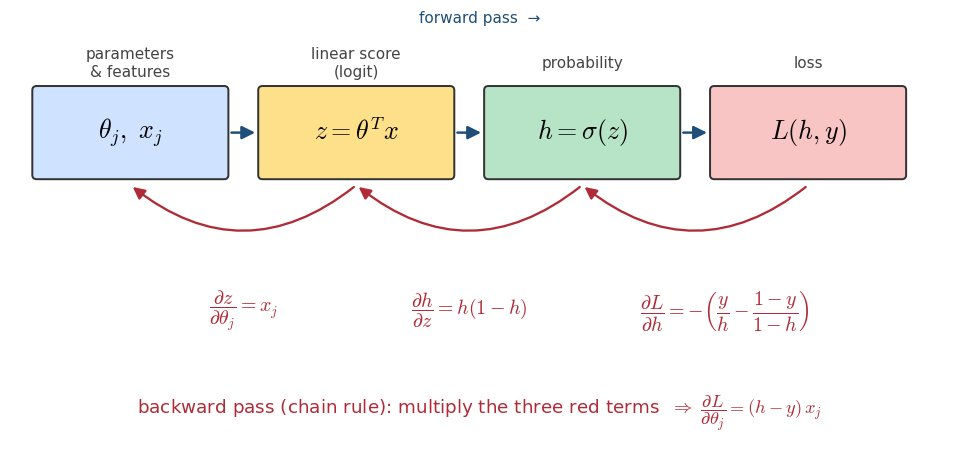



# Algorithm: Gradient Descent for Logistic Regression


\begin{array}{ll}
\textbf{Input:} & X,\ y,\ \alpha=0.01,\ T=1000\\
\textbf{Output:} & \theta,\ \text{loss\_history}
\end{array}


\begin{aligned}
&\textbf{Begin}\\
&\quad m \gets \text{number of samples in } X\\
&\quad n \gets \text{number of features in } X\\
&\quad \theta \gets \mathbf{0}_{n\times 1}\\
&\quad \text{loss\_history} \gets [\,]\\[2pt]
&\quad \textbf{For } t=1 \textbf{ to } T \textbf{ do}\\
&\qquad z \gets X\theta\\
&\qquad \hat{y} \gets \sigma(z)
       = \frac{1}{1+e^{-z}}\\
&\qquad e \gets \hat{y}-y\\
&\qquad g \gets \frac{1}{m}X^{\top}e\\
&\qquad \theta \gets \theta-\alpha g\\
&\qquad L \gets \operatorname{ComputeLoss}(y,\hat{y})\\
&\qquad \text{Append } L \text{ to loss\_history}\\
&\quad \textbf{End For}\\[2pt]
&\quad \textbf{Return } \theta,\ \text{loss\_history}\\
&\textbf{End}
\end{aligned}
\]


In [91]:
def gradient_descent(X, y, lr=0.1, epochs=1000):
    m, n = X.shape
    theta = np.zeros((n, 1))
    loss_history = []

    for t in range(epochs):
        z = np.dot(X, theta)
        y_pred = sigmoid(z)
        error = y_pred - y
        gradient = (1/m) * np.dot(X.T, error)
        theta = theta - lr * gradient

        loss = compute_loss(y, y_pred)
        loss_history.append(loss)

    return theta, loss_history

# ---------------------------
# Step 5: Train Model
# ---------------------------

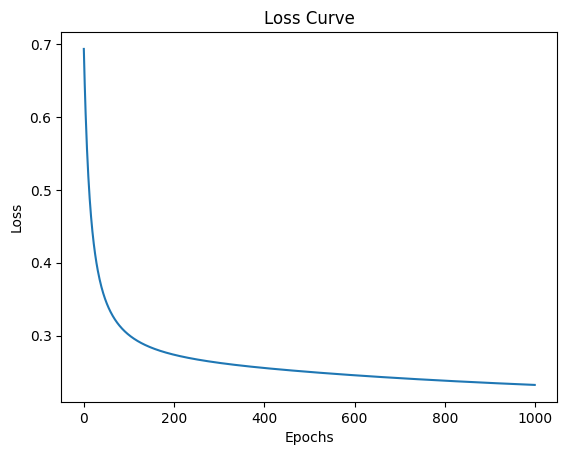

In [92]:

theta, loss_history = gradient_descent(X, y, lr=0.1, epochs=1000)

# ---------------------------
# Step 6: Predictions
# ---------------------------
y_pred_prob = sigmoid(np.dot(X, theta))
y_pred = (y_pred_prob >= 0.5).astype(int)

# ---------------------------
# Step 7: Plot Loss Curve
# ---------------------------
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.show()

### Precision, Recall, F1-score and Accuracy

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | $\dfrac{TP + TN}{TP + TN + FP + FN}$ | What fraction of *all* predictions are correct? (overall correctness) |
| **Precision** | $\dfrac{TP}{TP + FP}$ | Of everything I *predicted* positive, how much really is positive? (accuracy of the positive predictions) |
| **Recall** (Sensitivity, TPR) | $\dfrac{TP}{TP + FN}$ | Of all *actual* positives, how many did I catch? |
| **F1-score** | $2 \times \dfrac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ | Harmonic mean — balances precision and recall; useful when classes are **imbalanced** |

💡 **When to care about which?**
- **High recall** matters when *missing* a positive is costly (disease screening, fraud detection).
- **High precision** matters when a *false alarm* is costly (spam filter deleting real emails).

🔗 More: https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall

🧪 Compute the metrics **from scratch** and compare with scikit-learn's `classification_report`:

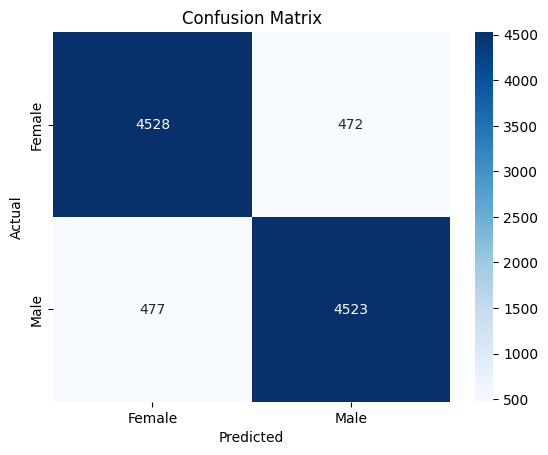

              precision    recall  f1-score   support

      Female       0.90      0.91      0.91      5000
        Male       0.91      0.90      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [84]:
# ---------------------------
# Step 8: Confusion Matrix
# ---------------------------
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Female", "Male"],
            yticklabels=["Female", "Male"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ---------------------------
# Step 9: Classification Report
# ---------------------------
print(classification_report(y, y_pred, target_names=["Female", "Male"]))

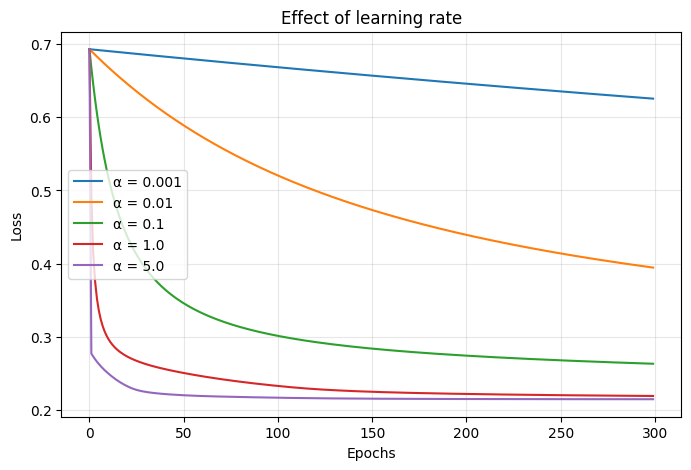

In [85]:
plt.figure(figsize=(8, 5))
for lr in [0.001, 0.01, 0.1, 1.0, 5.0]:
    _, hist = gradient_descent(X, y, lr=lr, epochs=300)
    plt.plot(hist, label=f"α = {lr}")
plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.title("Effect of learning rate")
plt.legend(); plt.grid(alpha=0.3); plt.show()

<h2 style="color:purple">Exercise</h2>

Download employee retention dataset from here: https://www.kaggle.com/giripujar/hr-analytics.
1. Now do some exploratory data analysis to figure out which variables have direct and clear impact on employee retention (i.e. whether they leave the company or continue to work)
2. Plot bar charts showing impact of employee salaries on retention
3. Plot bar charts showing corelation between department and employee retention
4. Now build logistic regression model using variables that were narrowed down in step 1
5. Measure the accuracy of the model

Dataset Shape: (14999, 10)

First 5 rows:
   satisfaction_level  last_evaluation  number_project  average_montly_hours  \
0                0.38             0.53               2                   157   
1                0.80             0.86               5                   262   
2                0.11             0.88               7                   272   
3                0.72             0.87               5                   223   
4                0.37             0.52               2                   159   

   time_spend_company  Work_accident  left  promotion_last_5years Department  \
0                   3              0     1                      0      sales   
1                   6              0     1                      0      sales   
2                   4              0     1                      0      sales   
3                   5              0     1                      0      sales   
4                   3              0     1                      0      sales 

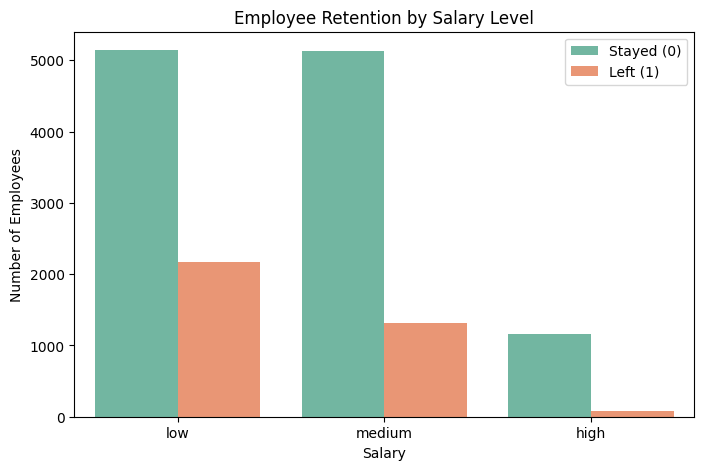

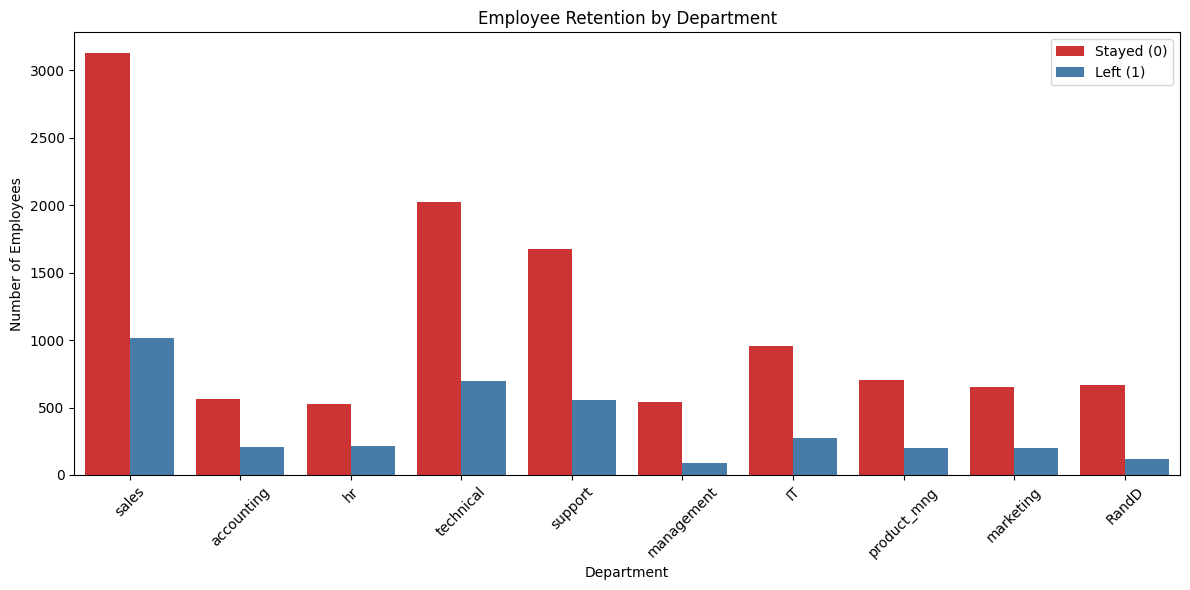


Logistic Regression Model Accuracy: 76.76%


In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import os

# 1. Download/Load the dataset
# Since downloading directly from Kaggle requires credentials, we will download a direct public mirror of the HR analytics dataset.
hr_url = 'https://raw.githubusercontent.com/codebasics/py/master/ML/7_logistic_reg/Exercise/HR_comma_sep.csv'
df_hr = pd.read_csv(hr_url)
print("Dataset Shape:", df_hr.shape)
print("\nFirst 5 rows:")
print(df_hr.head())

# 2. Exploratory Data Analysis
print("\nAverage numbers for people who left vs. stayed:")
left_analysis = df_hr.groupby('left').mean(numeric_only=True)
print(left_analysis)

# 3. Bar chart showing impact of employee salaries on retention
plt.figure(figsize=(8, 5))
sns.countplot(data=df_hr, x='salary', hue='left', palette='Set2')
plt.title('Employee Retention by Salary Level')
plt.xlabel('Salary')
plt.ylabel('Number of Employees')
plt.legend(['Stayed (0)', 'Left (1)'])
plt.show()

# 4. Bar chart showing correlation between department and employee retention
plt.figure(figsize=(12, 6))
sns.countplot(data=df_hr, x='Department', hue='left', palette='Set1')
plt.title('Employee Retention by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=45)
plt.legend(['Stayed (0)', 'Left (1)'])
plt.tight_layout()
plt.show()

# 5. Build Logistic Regression model using narrowed down variables
# From the EDA, we select influential features:
# - satisfaction_level (strong impact)
# - average_montly_hours (impact)
# - promotion_last_5years (impact)
# - salary (strong impact, needs dummy encoding)

sub_df = df_hr[['satisfaction_level', 'average_montly_hours', 'promotion_last_5years', 'salary']]
salary_dummies = pd.get_dummies(sub_df['salary'], prefix='salary', drop_first=True)

# Combine features
X_hr = pd.concat([sub_df.drop('salary', axis=1), salary_dummies], axis=1)
y_hr = df_hr['left']

# Split data
X_train_hr, X_test_hr, y_train_hr, y_test_hr = train_test_split(X_hr, y_hr, test_size=0.3, random_state=42)

# Train model
hr_model = LogisticRegression(max_iter=1000)
hr_model.fit(X_train_hr, y_train_hr)

# Evaluate accuracy
y_pred_hr = hr_model.predict(X_test_hr)
accuracy = accuracy_score(y_test_hr, y_pred_hr)
print(f"\nLogistic Regression Model Accuracy: {accuracy * 100:.2f}%")